# **Problem Statement**

## **Business Context**

Workplace safety in hazardous environments like construction sites and industrial plants is crucial to prevent accidents and injuries. One of the most important safety measures is ensuring workers wear safety helmets, which protect against head injuries from falling objects and machinery. Non-compliance with helmet regulations increases the risk of serious injuries or fatalities, making effective monitoring essential, especially in large-scale operations where manual oversight is prone to errors and inefficiency.

To overcome these challenges, SafeGuard Corp plans to develop an automated image analysis system capable of detecting whether workers are wearing safety helmets. This system will improve safety enforcement, ensuring compliance and reducing the risk of head injuries. By automating helmet monitoring, SafeGuard aims to enhance efficiency, scalability, and accuracy, ultimately fostering a safer work environment while minimizing human error in safety oversight.

## **Objective**

As a data scientist at SafeGuard Corp, you are tasked with developing an image classification model that classifies images into one of two categories:
- **With Helmet:** Workers wearing safety helmets.
- **Without Helmet:** Workers not wearing safety helmets.

## **Data Description**

The dataset consists of **631 images**, equally divided into two categories:

- **With Helmet:** 311 images showing workers wearing helmets.
- **Without Helmet:** 320 images showing workers not wearing helmets.

**Dataset Characteristics:**
- **Variations in Conditions:** Images include diverse environments such as construction sites, factories, and industrial settings, with variations in lighting, angles, and worker postures to simulate real-world conditions.
- **Worker Activities:** Workers are depicted in different actions such as standing, using tools, or moving, ensuring robust model learning for various scenarios.

# **Installing and Importing the Necessary Libraries**

In [ ]:
!pip install tensorflow[and-cuda] scikit-learn==1.6.1 opencv-python==4.12.0.88 seaborn==0.13.2 matplotlib==3.10.0 numpy==2.0.2 pandas==2.2.2 -q

In [ ]:
import tensorflow as tf
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))
print(tf.__version__)

Num GPUs Available: 1
2.19.0


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:
import os
import random
import numpy as np                                                                               # Importing numpy for Matrix Operations
import pandas as pd
import seaborn as sns
import matplotlib.image as mpimg                                                                              # Importing pandas to read CSV files
import matplotlib.pyplot as plt                                                                  # Importting matplotlib for Plotting and visualizing images
import math                                                                                      # Importing math module to perform mathematical operations
import cv2


# Tensorflow modules
import keras
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator                              # Importing the ImageDataGenerator for data augmentation
from tensorflow.keras.models import Sequential                                                   # Importing the sequential module to define a sequential model
from tensorflow.keras.layers import Dense,Dropout,Flatten,Conv2D,MaxPooling2D,BatchNormalization # Defining all the layers to build our CNN Model
from tensorflow.keras.optimizers import Adam,SGD                                                 # Importing the optimizers which can be used in our model
from sklearn import preprocessing                                                                # Importing the preprocessing module to preprocess the data
from sklearn.model_selection import train_test_split                                             # Importing train_test_split function to split the data into train and test
from sklearn.metrics import confusion_matrix
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import F1Score, Accuracy, Precision, Recall
from keras.applications.vgg16 import VGG16                                               # Importing confusion_matrix to plot the confusion matrix

# Display images using OpenCV
from google.colab.patches import cv2_imshow

#Imports functions for evaluating the performance of machine learning models
from sklearn.metrics import confusion_matrix, f1_score,accuracy_score, recall_score, precision_score, classification_report
from sklearn.metrics import mean_squared_error as  mse                                      # Importing cv2_imshow from google.patches to display images

from sklearn.model_selection import train_test_split

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Set the seed using keras.utils.set_random_seed. This will set:
# 1) `numpy` seed
# 2) backend random seed
# 3) `python` random seed
tf.keras.utils.set_random_seed(812)

# **Data Overview**


##Loading the data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
labels = pd.read_csv('/content/drive/MyDrive/AIML/Project6/Labels_proj.csv')
images = np.load('/content/drive/MyDrive/AIML/Project6/images_proj.npy')

In [ ]:
print(labels.shape)
print(images.shape)

(631, 1)
(631, 200, 200, 3)


**OBSERVATIONS**:

---
- There are 631 labels and 631 RGB images of dimensions: 200x200 with 3 color channels




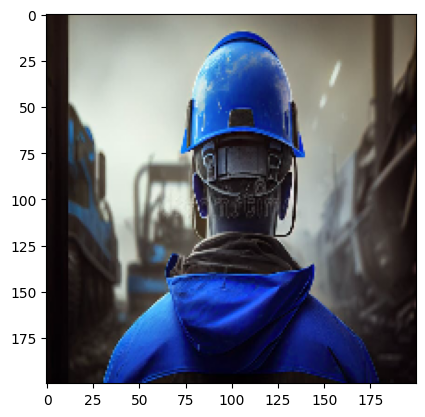

In [ ]:
plt.imshow(images[16])

In [ ]:
def plot_images(images,labels):
  num_classes=10                                                                  # Number of Classes
  categories=np.unique(labels)
  keys=dict(labels['Label'])                                                      # Obtaing the unique classes from y_train
  rows = 3                                                                        # Defining number of rows=3
  cols = 4                                                                        # Defining number of columns=4
  fig = plt.figure(figsize=(10, 8))                                               # Defining the figure size to 10x8
  for i in range(cols):
      for j in range(rows):
          random_index = np.random.randint(0, len(labels))                        # Generating random indices from the data and plotting the images
          ax = fig.add_subplot(rows, cols, i * rows + j + 1)                      # Adding subplots with 3 rows and 4 columns
          ax.imshow(images[random_index, :])                                      # Plotting the image
          ax.set_title(keys[random_index])
  plt.show()

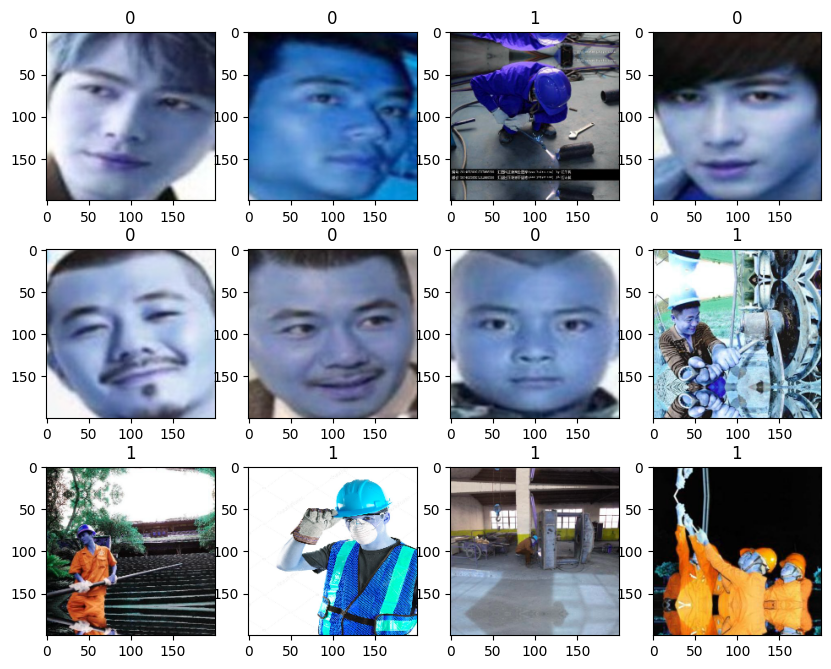

In [ ]:
plot_images(images,labels)

# **Exploratory Data Analysis**

###Plot random images from each of the classes and print their corresponding labels.

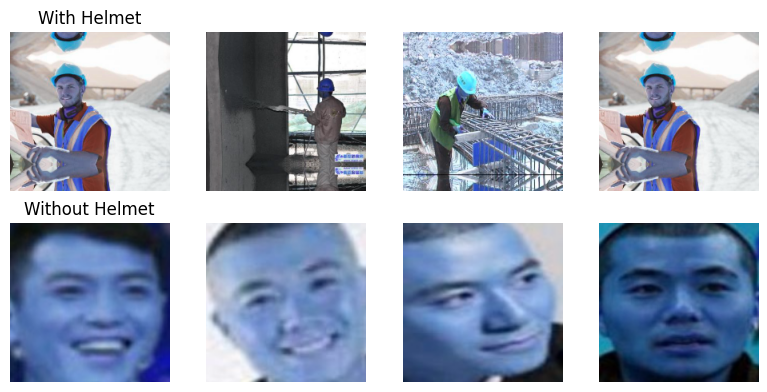

In [ ]:
helmet_indices = np.where(labels['Label'] == 1)[0]
no_helmet_indices = np.where(labels['Label'] == 0)[0]

# Select one 4 image from each class
helmet_img = np.zeros((4, 200, 200, 3), dtype=np.uint8)
no_helmet_img = np.zeros((4, 200, 200, 3), dtype=np.uint8)
for i in range(4):
  helmet_img[i] = images[np.random.choice(helmet_indices)]
  no_helmet_img[i] = images[np.random.choice(no_helmet_indices)]

# Plot the images
fig, axes = plt.subplots(2, 4, figsize=(8, 4))

# Display "With Helmet" images
axes[0, 0].set_title("With Helmet")
for i in range(4):
  axes[0, i].imshow(helmet_img[i])
  axes[0, i].axis('off')


# Display "Without Helmet" images
axes[1, 0].set_title("Without Helmet")
for i in range(4):
  axes[1, i].imshow(no_helmet_img[i])
  axes[1, i].axis('off')

# Show the plots
plt.tight_layout()
plt.show()

**OBSERVATIONS**:


---
- We printed 4 random images with helmets and 4 without helmets. It seems like the images with helmets are more zoomed out with background, whereas the images without hemets seem zoomed in on the face with no background.
- For having a better model, we should probably add images with background for sample set of images-without-hemets.
- The color channels and seems to be not uniformly present for an RGB picture. Some color channels might not have data. However, this will not interfere with our helmet recognition since the quality of the photos seems to be good enough to distinguish between workers with helmets and without one.




## Checking for class imbalance


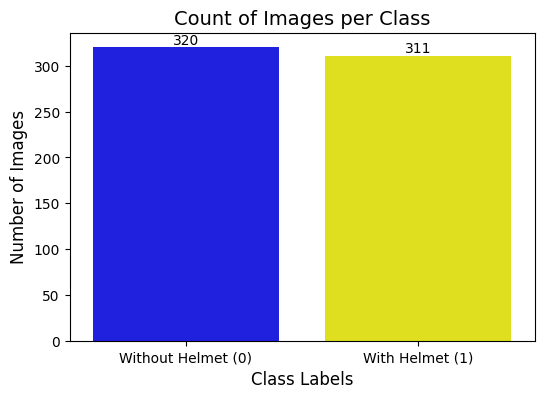

In [ ]:
# Create a count plot
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=labels.iloc[:, 0], palette=['blue', 'yellow'])

# Add exact counts on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10, )

# Add labels
plt.xlabel("Class Labels", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)
plt.title("Count of Images per Class", fontsize=14)
plt.xticks(ticks=[0, 1], labels=["Without Helmet (0)", "With Helmet (1)"])  # Rename x-axis labels

# Show plot
plt.show()

**OBSERVATIONS**:


---
- The dataset seems to be well balanced to provide similar number of images for both the classes for classification with 320 without helmet images and 311 with helmet images


# **Data Preprocessing**

## Converting images to grayscale

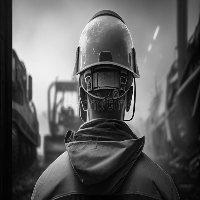

In [ ]:
images_gray = []
for i in range(len(images)):
    img_gray = cv2.cvtColor(images[i], cv2.COLOR_BGR2GRAY)  # Convert to grayscale
    images_gray.append(img_gray)

# Display a sample grayscale image
n = 16
cv2_imshow(images_gray[n])

**OBSERVATIONS**:


---
- For our base model, we convert the images to grayscale for faster computation by reducing the number of channels


### Splitting the dataset (for gray_scaled images)



In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(np.array(images_gray),labels , test_size=0.2, random_state=42,stratify=labels)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp , test_size=0.2, random_state=42,stratify=y_temp)

In [ ]:
print(X_train.shape,y_train.shape)
print(X_val.shape,y_val.shape)
print(X_test.shape,y_test.shape)

(504, 200, 200) (504, 1)
(101, 200, 200) (101, 1)
(26, 200, 200) (26, 1)


**OBSERVATIONS**:


---
- We split the dataset into training : validation : testing sets with the 20:4:1 ratio.
- So the number of grayscale images in our sets are as follows:
  - training: 504
  - validation: 101
  - testing: 26


### Data Normalization

In [ ]:
X_train_normalized = X_train.astype('float32')/255.0
X_val_normalized = X_val.astype('float32')/255.0
X_test_normalized = X_test.astype('float32')/255.0

**OBSERVATIONS**:


---
- We normalized the grayscale images by dividing the values by 255.0 to improve model convergence (reach global maxima sooner) and also to prevent high pixel values to dominate over the other values.


# **Model Building**

##Model Evaluation Criterion


- We will be computing 4 performance metrics: accuracy, reall, precision and f1-score, but will focus on **accuracy first**, since classifying the images accurately is our primary goal.
- Secondly, we have more to lose to **false positives** ( detecting workers-without-helmets as workers-with-helmet). So, our **secondary** importance is on **Precision**


## Utility Functions

In [ ]:
# compute different metrics to check performance of a classification model built using statsmodels
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)


    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average='weighted')  # to compute Recall
    precision = precision_score(target, pred, average='weighted')  # to compute Precision
    f1 = f1_score(target, pred, average='weighted')  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame({"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1,},index=[0],)

    return df_perf

In [ ]:
def plot_confusion_matrix(model,predictors,target,ml=False):
    """
    Function to plot the confusion matrix

    model: classifier
    predictors: independent variables
    target: dependent variable
    ml: To specify if the model used is an sklearn ML model or not (True means ML model)
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)

    # Plotting the Confusion Matrix using confusion matrix() function which is also predefined tensorflow module
    confusion_matrix = tf.math.confusion_matrix(target,pred)
    f, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(
        confusion_matrix,
        annot=True,
        linewidths=.4,
        fmt="d",
        square=True,
        ax=ax
    )
    plt.show()

In [ ]:
# alternate plotting method.. not currently used..
def compare_training_validation_performance(model, train_predictors, train_target, val_predictors, val_target):
    """
    Function to compare training and validation performance of a classifier and plot confusion matrices side-by-side.

    model: classifier to evaluate
    train_predictors: independent variables for training data
    train_target: dependent variable for training data
    val_predictors: independent variables for validation data
    val_target: dependent variable for validation data
    """

    # Calculate and print performance metrics
    train_perf = model_performance_classification(model, train_predictors, train_target)
    val_perf = model_performance_classification(model, val_predictors, val_target)

    print("Train performance metrics:")
    print(train_perf)
    print("\nValidation performance metrics:")
    print(val_perf)

    print("\nConfusion Matrices:")


    # Calculate predictions
    train_pred = model.predict(train_predictors).reshape(-1) > 0.5
    val_pred = model.predict(val_predictors).reshape(-1) > 0.5

    # Get true targets as numpy arrays
    train_target_np = train_target.to_numpy().reshape(-1)
    val_target_np = val_target.to_numpy().reshape(-1)

    # Compute confusion matrices
    train_cm = tf.math.confusion_matrix(train_target_np, train_pred)
    val_cm = tf.math.confusion_matrix(val_target_np, val_pred)

    # Plot confusion matrices side by side
    fig, axes = plt.subplots(1, 2, figsize=(8, 5)) # Create a figure with 2 subplots side-by-side
    sns.heatmap(
        train_cm,
        annot=True,
        linewidths=.4,
        fmt="d",
        square=True,
        ax=axes[0]
    )
    axes[0].set_title("Training Confusion Matrix")
    axes[0].set_xlabel("Predicted Label")
    axes[0].set_ylabel("True Label")

    sns.heatmap(
        val_cm,
        annot=True,
        linewidths=.4,
        fmt="d",
        square=True,
        ax=axes[1]
    )
    axes[1].set_title("Validation Confusion Matrix")
    axes[1].set_xlabel("Predicted Label")
    axes[1].set_ylabel("True Label")

    plt.tight_layout() # Adjust subplot parameters for a tight layout
    plt.show()

##Model 1: Simple Convolutional Neural Network (CNN)

- Let's start with a simple convolutional neural network with 3 convolutional layers and 1 output layer.

In [ ]:
# Initializing Model
model_1 = Sequential()

# Convolutional layers
model_1.add(Conv2D(32, (3, 3), activation='relu', padding="same", input_shape=(200,200,1)))# 1 channel since we are using grayscale
model_1.add(MaxPooling2D((4, 4), padding='same'))
model_1.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
model_1.add(MaxPooling2D((4,4), padding='same'))
model_1.add(Conv2D(32, (3, 3), activation='relu', padding="same"))

# Flatten and Dense layers
model_1.add(Flatten())
model_1.add(Dense(4, activation='relu'))
model_1.add(Dense(1, activation='sigmoid'))  #since we want binary classification

# Compile with Adam Optimizer
opt = Adam(learning_rate=0.001)
model_1.compile(optimizer=opt, loss='binary_crossentropy', metrics=["accuracy",tf.keras.metrics.Precision()])

# Summary
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 200, 200, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 50, 50, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 13, 13, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │        21,636 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,457 (158.04 KB)

 Trainable params: 40,457 (158.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_1 = model_1.fit(
            X_train_normalized, y_train,
            epochs=10,
            validation_data=(X_val_normalized,y_val),
            shuffle=True,
            batch_size=50,
            verbose=2
)

Epoch 1/10
11/11 - 21s - 2s/step - accuracy: 0.4901 - loss: 0.6601 - precision: 0.4911 - val_accuracy: 0.4950 - val_loss: 0.5562 - val_precision: 0.4950
Epoch 2/10
11/11 - 5s - 444ms/step - accuracy: 0.6905 - loss: 0.4593 - precision: 0.6139 - val_accuracy: 0.9604 - val_loss: 0.3659 - val_precision: 0.9259
Epoch 3/10
11/11 - 0s - 30ms/step - accuracy: 0.9683 - loss: 0.3628 - precision: 0.9394 - val_accuracy: 1.0000 - val_loss: 0.3550 - val_precision: 1.0000
Epoch 4/10
11/11 - 1s - 54ms/step - accuracy: 0.9841 - loss: 0.3552 - precision: 0.9688 - val_accuracy: 0.9802 - val_loss: 0.3569 - val_precision: 1.0000
Epoch 5/10
11/11 - 0s - 28ms/step - accuracy: 0.9821 - loss: 0.3488 - precision: 0.9650 - val_accuracy: 0.9802 - val_loss: 0.3559 - val_precision: 1.0000
Epoch 6/10
11/11 - 0s - 34ms/step - accuracy: 0.9940 - loss: 0.3538 - precision: 0.9920 - val_accuracy: 1.0000 - val_loss: 0.3373 - val_precision: 1.0000
Epoch 7/10
11/11 - 0s - 33ms/step - accuracy: 0.9980 - loss: 0.3401 - precis

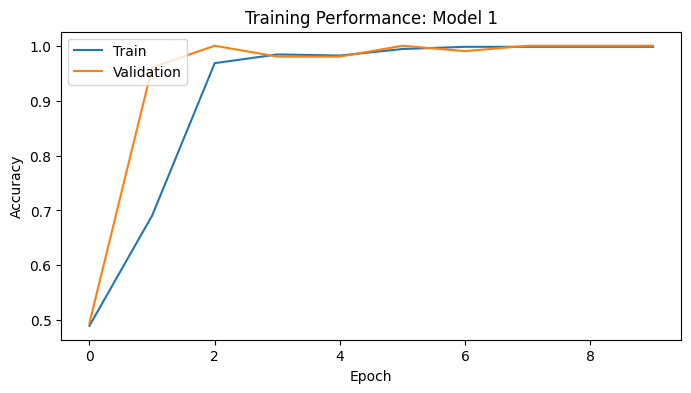

In [ ]:
plt.figure(figsize=(8,4))
plt.plot(history_1.history['accuracy'])
plt.plot(history_1.history['val_accuracy'])
plt.title('Training Performance: Model 1')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

### Compare performance: Model 1

In [ ]:
model_1_train_perf = model_performance_classification(model_1,X_train_normalized,y_train)

print("Train performance metrics")
print(model_1_train_perf)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step
Train performance metrics
   Accuracy    Recall  Precision  F1 Score
0  0.998016  0.998016   0.998024  0.998016


In [ ]:
model_1_valid_perf = model_performance_classification(model_1, X_val_normalized,y_val)

print("Validation performance metrics")
print(model_1_valid_perf)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
Validation performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


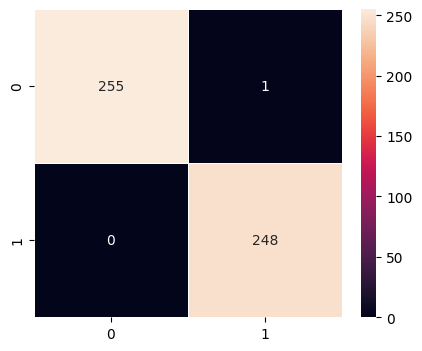

In [ ]:
plot_confusion_matrix(model_1,X_train_normalized,y_train)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


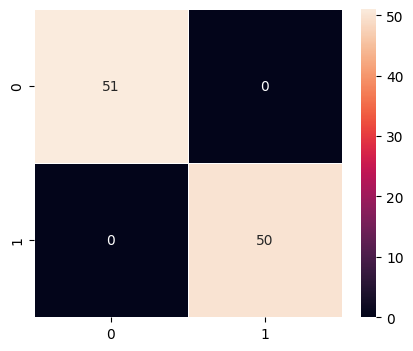

In [ ]:
plot_confusion_matrix(model_1,X_val_normalized,y_val)

### Vizualizing the predictions

In [ ]:
X_val_normalized.shape

(101, 200, 200)

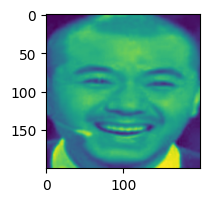

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 385ms/step
Predicted Label: 1
True Label: Label    0
Name: 405, dtype: int64


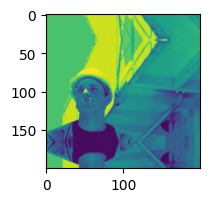

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Predicted Label: 1
True Label: Label    1
Name: 52, dtype: int64


In [ ]:
# For index 16
plt.figure(figsize=(2,2))
plt.imshow(X_val[16])
plt.show()
prediction = model_1.predict(X_val_normalized[2].reshape(1,200,200))
predicted_label = prediction[0][0]>0.5  # Extract the predicted class label
print('Predicted Label:', 1 if predicted_label else 0)
# Fix indexing issue in y_val
true_label = y_val.iloc[16]
print('True Label:', true_label)

# For index 32
plt.figure(figsize=(2,2))
plt.imshow(X_val[32])
plt.show()
prediction = model_1.predict(X_val_normalized[2].reshape(1,200,200))
predicted_label = prediction[0][0]>0.5  # Extract the predicted class label
print('Predicted Label:', 1 if predicted_label else 0)
# Fix indexing issue in y_val
true_label = y_val.iloc[32]
print('True Label:', true_label)

**OBSERVATIONS**:


---
- For **Model 1** we used **CNN** with 3 convolution layers, 1 flatten layer, 1 additional layer, 1 output layer. We used Adam optimizer with 0.001 learning rate.
- Performance on training data: 99.8% accuracy and 99.8% precision
- Performance on validation data: is perfect with 100% accuracy and 100% precision
- Performance on test data (images at index: 16, 32): The prediction for image at index 16 was incorrect (predicted helmet(1), image did not have helmet(0)).
- Conclusion:
  - The model has near perfect performance. Based on the graph too, the performance flattens after 3 epochs.
  - Although this is a good model that may work for small datasets that are similar to what we trained on, this model maybe overfitting on this dataset and will not generalize well on unseen data because our model does not have any  regularization.
  




## Model 2: (VGG-16 (Base))

- For VGG-16, if we plan to do transfer learning, we need to use colored images in our training set since VGG-16 uses colored images.
- Hence redefining the training and valiidation datasets using colored images

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(np.array(images),labels , test_size=0.2, random_state=42,stratify=labels)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp , test_size=0.2, random_state=42,stratify=y_temp)

In [ ]:
print(X_train.shape,y_train.shape)
print(X_val.shape,y_val.shape)
print(X_test.shape,y_test.shape)

(504, 200, 200, 3) (504, 1)
(101, 200, 200, 3) (101, 1)
(26, 200, 200, 3) (26, 1)


In [ ]:
X_train_normalized = X_train.astype('float32')/255.0
X_val_normalized = X_val.astype('float32')/255.0
X_test_normalized = X_test.astype('float32')/255.0

In [ ]:
vgg_model = VGG16(weights='imagenet',include_top=False,input_shape=(200,200,3))
vgg_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 200, 200, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 100, 100, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 100, 100, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 50, 50, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 25, 25, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 12, 12, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 6, 6, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Making all the layers of the VGG model non-trainable
for layer in vgg_model.layers:
    layer.trainable = False

In [ ]:
model_2 = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_2.add(vgg_model)

# Flattening the output of the VGG16 model because it is from a convolutional layer
model_2.add(Flatten())

# Adding a dense output layer
model_2.add(Dense(1, activation='sigmoid'))

In [ ]:
opt=Adam(learning_rate=0.001)
# Compile model
model_2.compile(optimizer=opt, loss=keras.losses.BinaryCrossentropy(), metrics=["accuracy"])

In [ ]:
# Generating the summary of the model
model_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │        18,433 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,733,121 (56.20 MB)

 Trainable params: 18,433 (72.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
train_datagen = ImageDataGenerator()

In [ ]:
# Epochs
epochs = 10
# Batch size
batch_size = 50

history_2 = model_2.fit(train_datagen.flow(X_train_normalized,y_train,
                                      batch_size=batch_size,
                                      seed=42,
                                      shuffle=False),
                    epochs=epochs,
                    steps_per_epoch=X_train_normalized.shape[0] // batch_size,
                    validation_data=(X_val_normalized,y_val),
                    verbose=1)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 39s 3s/step - accuracy: 0.7256 - loss: 0.4923 - val_accuracy: 1.0000 - val_loss: 0.0306
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 1.0000 - loss: 0.0390 - val_accuracy: 1.0000 - val_loss: 0.0260
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 261ms/step - accuracy: 0.9985 - loss: 0.0255 - val_accuracy: 1.0000 - val_loss: 0.0063
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 1.0000 - loss: 0.0079 - val_accuracy: 1.0000 - val_loss: 0.0059
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 269ms/step - accuracy: 1.0000 - loss: 0.0057 - val_accuracy: 1.0000 - val_loss: 0.0044
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 1.0000 - loss: 0.0044 - val_accuracy: 1.0000 - val_loss: 0.0044
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 263ms/step - accuracy: 1.0000 - loss: 0.0033 - val_accuracy: 1.0000 - val_loss: 0.0038
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 1.0000 - loss: 0.0042 - val_accuracy: 1.0000 -

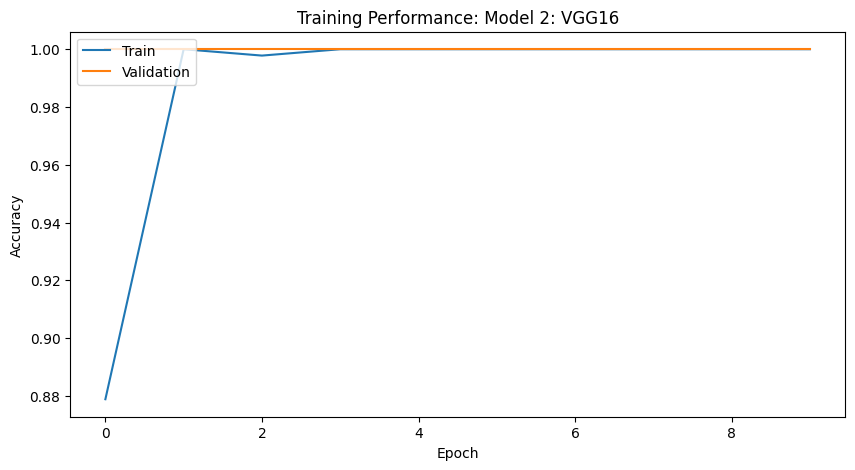

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(history_2.history['accuracy'])
plt.plot(history_2.history['val_accuracy'])
plt.title('Training Performance: Model 2: VGG16')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
model_2_train_perf = model_performance_classification(model_2,X_train_normalized,y_train)

print("Train performance metrics")
print(model_2_train_perf)

16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 627ms/step
Train performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


In [ ]:
model_2_valid_perf = model_performance_classification(model_2, X_val_normalized,y_val)

print("Validation performance metrics")
print(model_2_valid_perf)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 249ms/step
Validation performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step


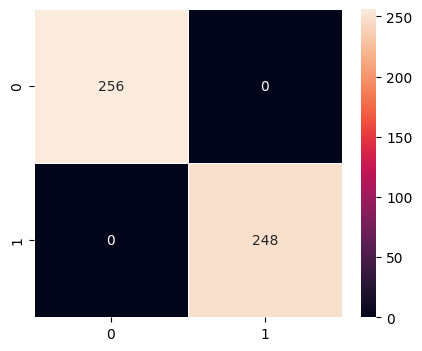

In [ ]:
plot_confusion_matrix(model_2,X_train_normalized,y_train)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step


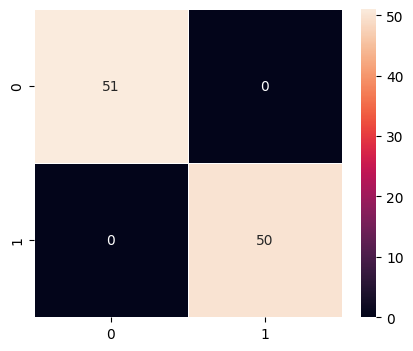

In [ ]:
plot_confusion_matrix(model_2,X_val_normalized,y_val)

### Visualizing the prediction:

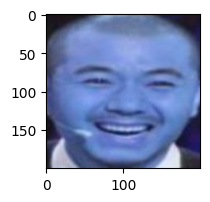

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Label: 0
True Label: Label    0
Name: 405, dtype: int64


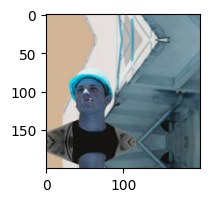

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Predicted Label: 1
True Label: Label    1
Name: 52, dtype: int64


In [ ]:
#for index 16
plt.figure(figsize=(2,2))
plt.imshow(X_val[16])
plt.show()
prediction = model_2.predict(X_val_normalized[16].reshape(1,200,200,3))
predicted_label = prediction[0][0]>0.5  # Extract the predicted class label
print('Predicted Label:', 1 if predicted_label else 0)
# Fix indexing issue in y_val
true_label = y_val.iloc[16]
print('True Label:', true_label)

#for index 32
plt.figure(figsize=(2,2))
plt.imshow(X_val[32])
plt.show()
prediction = model_2.predict(X_val_normalized[32].reshape(1,200,200,3))
predicted_label = prediction[0][0]>0.5  # Extract the predicted class label
print('Predicted Label:', 1 if predicted_label else 0)
# Fix indexing issue in y_val
true_label = y_val.iloc[32]
print('True Label:', true_label)

**OBSERVATIONS**:


---
- For Model 2 we used **VGG-16 Base Model**, and used colored images since VGG is trained on colored images. We freezed for training, and the rest of the model is similar to the previous one to evaluate on CNN vs VGG16.
- Performance on training data: Accuracy : 100%, Precision: 100%
- Performance on validation data: Accuracy : 100%, Precision: 100%
- Performance on test data (images at index: 16, 32): abels for both images were predicted correctly, unlike the previous model.
- Conclusion:
  - Since VGG-16 base model was trained on ImageNet, this model will do better at generalizing on unseen images when compared to Model 1.
  - By setting trainable = false also doesn't make the model overfit on this dataset
  - There is still additional scope for improving the model performance by performing other regularization techniques.

## Model 3: (VGG-16 (Base + FFNN))

In [ ]:
model_3 = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_3.add(vgg_model)

# Flattening the output of the VGG16 model because it is from a convolutional layer
model_3.add(Flatten())

#Adding the Feed Forward neural network
model_3.add(Dense(64,activation='relu'))
model_3.add(Dropout(rate=0.1))
model_3.add(Dense(32,activation='relu'))

# Adding a dense output layer
model_3.add(Dense(1, activation='sigmoid'))

In [ ]:
opt = Adam(learning_rate=0.001)

In [ ]:
# Compile model
model_3.compile(optimizer=opt,loss=keras.losses.BinaryCrossentropy(), metrics=["accuracy",tf.keras.metrics.Precision()])

In [ ]:
# Generating the summary of the model
model_3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │     1,179,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,896,513 (60.64 MB)

 Trainable params: 1,181,825 (4.51 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
history_3 = model_3.fit(train_datagen.flow(X_train_normalized,y_train,
                                       batch_size=50,
                                       seed=42,
                                       shuffle=False),
                    epochs=10,
                    steps_per_epoch=X_train_normalized.shape[0] // batch_size,
                    validation_data=(X_val_normalized,y_val),
                    verbose=1)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 636ms/step - accuracy: 0.8510 - loss: 0.2925 - precision_1: 0.8236 - val_accuracy: 1.0000 - val_loss: 2.1852e-04 - val_precision_1: 1.0000
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 1.0000 - loss: 0.0037 - precision_1: 1.0000 - val_accuracy: 1.0000 - val_loss: 6.4173e-05 - val_precision_1: 1.0000
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 278ms/step - accuracy: 0.9960 - loss: 0.0150 - precision_1: 0.9920 - val_accuracy: 1.0000 - val_loss: 6.4295e-06 - val_precision_1: 1.0000
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 1.0000 - loss: 2.9356e-04 - precision_1: 1.0000 - val_accuracy: 1.0000 - val_loss: 5.9703e-06 - val_precision_1: 1.0000
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 270ms/step - accuracy: 1.0000 - loss: 0.0012 - precision_1: 1.0000 - val_accuracy: 1.0000 - val_loss: 5.0859e-05 - val_precision_1: 1.0000
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 1.0000 - loss: 2.0257e-04 - precisi

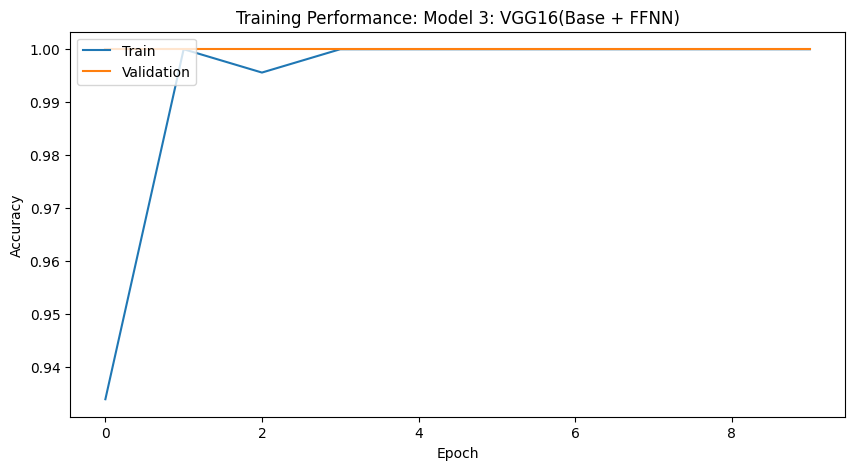

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(history_3.history['accuracy'])
plt.plot(history_3.history['val_accuracy'])
plt.title('Training Performance: Model 3: VGG16(Base + FFNN)')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
model_3_train_perf = model_performance_classification(model_3, X_train_normalized,y_train)

print("Train performance metrics")
print(model_3_train_perf)

16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 195ms/step
Train performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


In [ ]:
model_3_valid_perf = model_performance_classification(model_3, X_val_normalized,y_val)

print("Validation performance metrics")
print(model_3_valid_perf)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 253ms/step
Validation performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 148ms/step


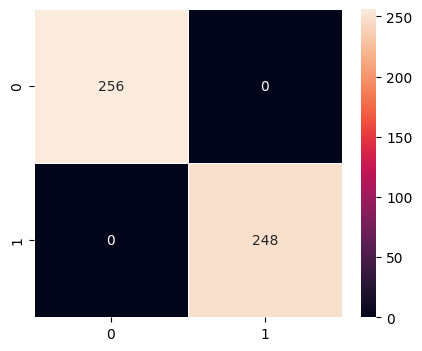

In [ ]:
plot_confusion_matrix(model_3,X_train_normalized,y_train)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step


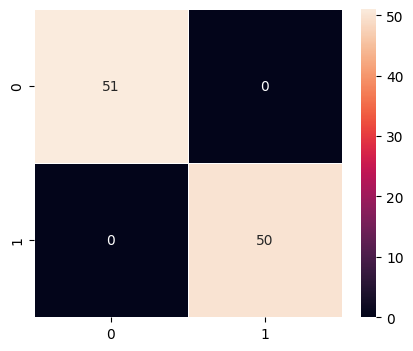

In [ ]:
plot_confusion_matrix(model_3,X_val_normalized,y_val)

#### Visualizing the predictions

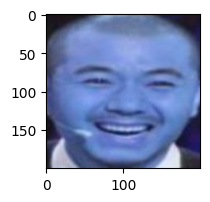

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Predicted Label: 0
True Label: Label    0
Name: 405, dtype: int64


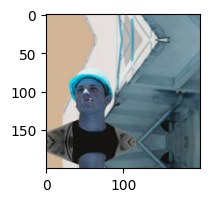

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Predicted Label: 1
True Label: Label    1
Name: 52, dtype: int64


In [ ]:
#For index 16
plt.figure(figsize=(2,2))
plt.imshow(X_val[16])
plt.show()
prediction = model_2.predict(X_val_normalized[16].reshape(1,200,200,3))
predicted_label = prediction[0][0]>0.5  # Extract the predicted class label
print('Predicted Label:', 1 if predicted_label else 0)
# Fix indexing issue in y_val
true_label = y_val.iloc[16]
print('True Label:', true_label)

#For index 32
plt.figure(figsize=(2,2))
plt.imshow(X_val[32])
plt.show()
prediction = model_2.predict(X_val_normalized[32].reshape(1,200,200,3))
predicted_label = prediction[0][0]>0.5  # Extract the predicted class label
print('Predicted Label:', 1 if predicted_label else 0)
# Fix indexing issue in y_val
true_label = y_val.iloc[32]
print('True Label:', true_label)

**OBSERVATIONS**:


---
- Model 3 contained **VGG-Base 16 Model with training enabled** to update layers, a FFN with 2 dense layers of 64 neurons and 32 neurons each, a dropout of 0.1, output layer of 1 neuron with a sigmoid activation function and Adam optimizer with a learning rate of 0.001
- Performance on training data: Accuracy : 100%, Precision: 100%
- Performance on validation data: Accuracy : 100%, Precision: 100%
- Performance on test data (images at index: 16, 32): labels for both images were predicted correctly
- Conclusion:
  - This model is better at handling overfitting because we also introduced a dropout of 0.1 as a regularization technique.
  - The FFN also helps in improving the training of the dataset
  - We can experiment with using data augmentation as another regularization mechanism in next model.


## Model 4: (VGG-16 (Base + FFNN + Data Augmentation)

- In most of the real-world case studies, it is challenging to acquire a large number of images and then train CNNs.
- To overcome this problem, one approach we might consider is **Data Augmentation**.
- CNNs have the property of **translational invariance**, which means they can recognise an object even if its appearance shifts translationally in some way. - Taking this attribute into account, we can augment the images using the techniques listed below

    -  Horizontal Flip (should be set to True/False)
    -  Vertical Flip (should be set to True/False)
    -  Height Shift (should be between 0 and 1)
    -  Width Shift (should be between 0 and 1)
    -  Rotation (should be between 0 and 180)
    -  Shear (should be between 0 and 1)
    -  Zoom (should be between 0 and 1) etc.

Remember, **data augmentation should not be used in the validation/test data set**.

In [ ]:
model_4 = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_4.add(vgg_model)

# Flattening the output of the VGG16 model because it is from a convolutional layer
model_4.add(Flatten())

#Adding the Feed Forward neural network
model_4.add(Dense(64,activation='relu'))
model_4.add(Dropout(rate=0.2))
model_4.add(Dense(32,activation='relu'))

# Adding a dense output layer
model_4.add(Dense(1, activation='sigmoid'))

In [ ]:
opt=Adam(learning_rate=0.001)
# Compile model
model_4.compile(optimizer=opt,   loss=keras.losses.BinaryCrossentropy(), metrics=["accuracy",tf.keras.metrics.Precision()])

In [ ]:
# Generating the summary of the model
model_4.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │     1,179,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,896,513 (60.64 MB)

 Trainable params: 1,181,825 (4.51 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
# Applying data augmentation
train_datagen = ImageDataGenerator(
                              rotation_range=45,
                              fill_mode='nearest',width_shift_range=0.2,height_shift_range=0.2,shear_range=0.2,zoom_range=0.2
                              )

In [ ]:
history_4 = model_4.fit(train_datagen.flow(X_train_normalized,y_train,
                                       batch_size=50,
                                       seed=42,
                                       shuffle=False),
                    epochs=epochs,
                    steps_per_epoch=X_train_normalized.shape[0] // batch_size,
                    validation_data=(X_val_normalized,y_val),
                    verbose=1)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.6968 - loss: 0.5871 - precision_2: 0.6785 - val_accuracy: 1.0000 - val_loss: 0.0097 - val_precision_2: 1.0000
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 1.0000 - loss: 0.0364 - precision_2: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0045 - val_precision_2: 1.0000
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 486ms/step - accuracy: 0.9910 - loss: 0.0337 - precision_2: 0.9910 - val_accuracy: 1.0000 - val_loss: 8.7266e-04 - val_precision_2: 1.0000
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 1.0000 - loss: 0.0118 - precision_2: 1.0000 - val_accuracy: 1.0000 - val_loss: 9.1387e-04 - val_precision_2: 1.0000
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 634ms/step - accuracy: 0.9968 - loss: 0.0095 - precision_2: 1.0000 - val_accuracy: 1.0000 - val_loss: 2.7784e-04 - val_precision_2: 1.0000
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 1.0000 - loss: 0.0073 - precision_2: 1.0000 - val

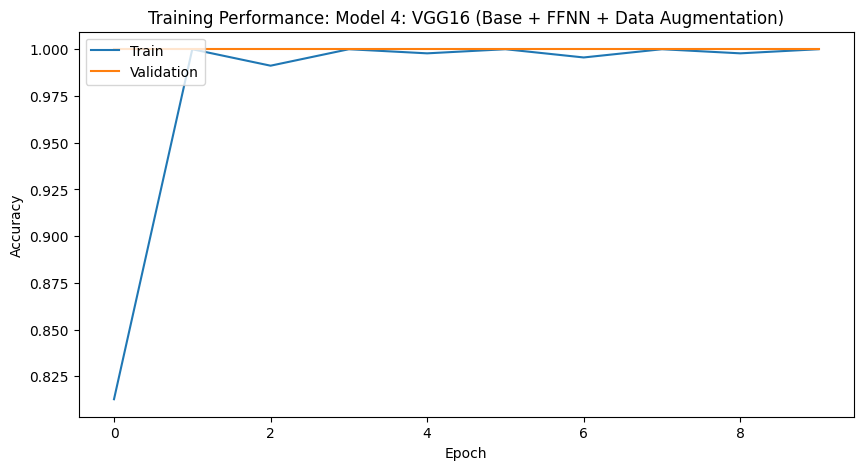

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(history_4.history['accuracy'])
plt.plot(history_4.history['val_accuracy'])
plt.title('Training Performance: Model 4: VGG16 (Base + FFNN + Data Augmentation)')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
model_4_train_perf = model_performance_classification(model_4, X_train_normalized,y_train)

print("Train performance metrics")
print(model_4_train_perf)

16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 195ms/step
Train performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


In [ ]:
model_4_valid_perf = model_performance_classification(model_4, X_val_normalized,y_val)

print("Validation performance metrics")
print(model_4_valid_perf)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 260ms/step
Validation performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 149ms/step


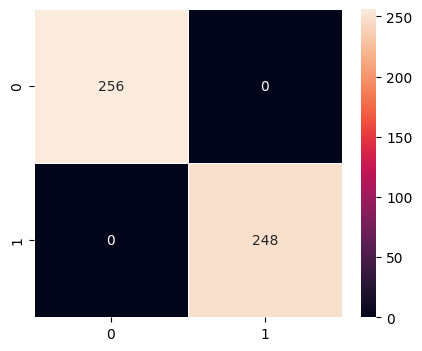

In [ ]:
plot_confusion_matrix(model_4,X_train_normalized,y_train)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step


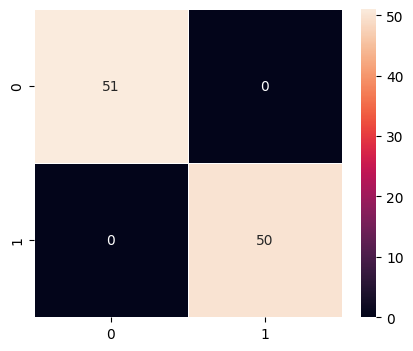

In [ ]:
plot_confusion_matrix(model_4,X_val_normalized,y_val)

#### Visualizing the predictions

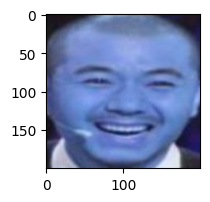

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Predicted Label: 0
True Label: Label    0
Name: 405, dtype: int64


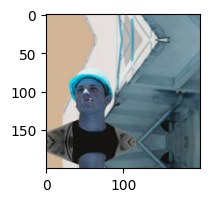

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Predicted Label: 1
True Label: Label    1
Name: 52, dtype: int64


In [ ]:
#for index 16
plt.figure(figsize=(2,2))
plt.imshow(X_val[16])
plt.show()
prediction = model_2.predict(X_val_normalized[16].reshape(1,200,200,3))
predicted_label = prediction[0][0]>0.5  # Extract the predicted class label
print('Predicted Label:', 1 if predicted_label else 0)
# Fix indexing issue in y_val
true_label = y_val.iloc[16]
print('True Label:', true_label)

#for index 32
plt.figure(figsize=(2,2))
plt.imshow(X_val[32])
plt.show()
prediction = model_2.predict(X_val_normalized[32].reshape(1,200,200,3))
predicted_label = prediction[0][0]>0.5  # Extract the predicted class label
print('Predicted Label:', 1 if predicted_label else 0)
# Fix indexing issue in y_val
true_label = y_val.iloc[32]
print('True Label:', true_label)

**OBSERVATIONS**:


---
- Model 4 used **VGG-Base 16** Model with **training enabled** to update layers, a **FFN with 2 dense layers** of 64 neurons and 32 neurons each, a dropout of 0.1, output layer of 1 neuron with a sigmoid activation function, Adam optimizer with a learning rate of 0.001 and **data augmentation using ImageGenerator**.
- Performance on training data: Accuracy : 100%, Precision: 100%
- Performance on validation data: Accuracy : 100%, Precision: 100%
- Performance on test data (images at index: 16, 32): labels for both images were predicted correctly
- Conclusion:
  - Data augmentation using ImageGenerator to update width, height, zoom, fill, rotation and sheer provides various different versions of the image to help the model generalize better on unseen image.
  - Both FFN and data augmentation will really help train our dataset better for prediction.
  - The performance on our dataset still remains perfect.
  

# **Model Performance Comparison and Final Model Selection**

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        model_1_train_perf.T,
        model_2_train_perf.T,
        model_3_train_perf.T,
        model_4_train_perf.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Simple Convolutional Neural Network (CNN)","VGG-16 (Base)","VGG-16 (Base+FFNN)","VGG-16 (Base+FFNN+Data Aug)"
]

In [ ]:
models_valid_comp_df = pd.concat(
    [
        model_1_valid_perf.T,
        model_2_valid_perf.T,
        model_3_valid_perf.T,
        model_4_valid_perf.T

    ],
    axis=1,
)
models_valid_comp_df.columns = [
 "Simple Convolutional Neural Network (CNN)","VGG-16 (Base)","VGG-16 (Base+FFNN)","VGG-16 (Base+FFNN+Data Aug)"
]

In [ ]:
models_train_comp_df

,Simple Convolutional Neural Network (CNN),VGG-16 (Base),VGG-16 (Base+FFNN),VGG-16 (Base+FFNN+Data Aug)
Accuracy,0.998016,1.0,1.0,1.0
Recall,0.998016,1.0,1.0,1.0
Precision,0.998024,1.0,1.0,1.0
F1 Score,0.998016,1.0,1.0,1.0


In [ ]:
models_valid_comp_df

,Simple Convolutional Neural Network (CNN),VGG-16 (Base),VGG-16 (Base+FFNN),VGG-16 (Base+FFNN+Data Aug)
Accuracy,1.0,1.0,1.0,1.0
Recall,1.0,1.0,1.0,1.0
Precision,1.0,1.0,1.0,1.0
F1 Score,1.0,1.0,1.0,1.0


In [ ]:
models_train_comp_df - models_valid_comp_df

,Simple Convolutional Neural Network (CNN),VGG-16 (Base),VGG-16 (Base+FFNN),VGG-16 (Base+FFNN+Data Aug)
Accuracy,-0.001984,0.0,0.0,0.0
Recall,-0.001984,0.0,0.0,0.0
Precision,-0.001976,0.0,0.0,0.0
F1 Score,-0.001984,0.0,0.0,0.0


### Observation:

- After comparing the results from the above tables, Model 2,3,4 perform really well on both accuracy and precision evaluation metrics for our dataset. We could choose either of the 3 based on our computation power, cost, etc.
- However, Model 4 will perform much better on large unseen dataset because we used VGG-16 model + a dense FFN along with all the necessary regularization techniques.

## Test Performance

In [ ]:
model_test_perf = model_performance_classification(model_4, X_test_normalized,y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


In [ ]:
model_test_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step


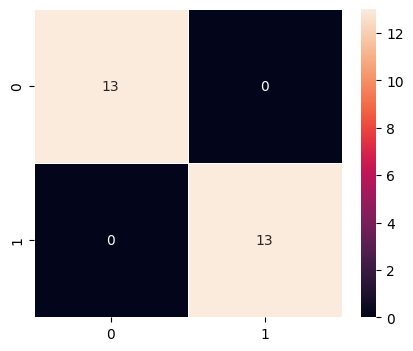

In [ ]:
plot_confusion_matrix(model_4, X_test_normalized,y_test)

**OBSERVATIONS**:


---
- Model 4 is performing well on test data too with perfect accuracy and precision
- On comparision of the models and selecting Model 4

# **Actionable Insights & Recommendations**

- Data set limitations:
  - We noticed that the dataset is quite limited with only 633 images. Also in these images, for the category of workers-without-helmet, the images were less diverse (all zoomed in on the face with little to no background)
  - Recommendation: The primary recommendation would be to get more images for training purposes, get diverse sizes and types of images as well as get more diverse variations of images-without-helmets.

- Model evaluations:
  - The performance on all 4 models is near perfect, with Models 2,3,4 better than Model 1 since they uses VGG-16 model which is trained on ImageNet.
  - Each model has been optimised to perform better than previous using better model, better training parameters, adding a feed forward NN,  using data augmentation for regularization to reduce overfitting.
  - The performance is perfect on all 3 models.
  - Hence the model that we choose as our final model will depend on our computation costs, time, and other parameters.
  - Recommendation: We are finalizing Model 4 for model deployment since it will perform the best for unseen data.

- Other recommendations:
  - These models can be further optimised by training with different filters, differenct variations of data augmentation parameters ( like skewing, rotating, zooming, cropping, too), learning rate, droput rate etc.
  - We can use other Transfer Learning architectures for training and then use model 4 for classification.

<font size=5 color='blue'>Power Ahead!</font>
___